In [72]:
#import libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

from sklearn.datasets import load_iris, fetch_california_housing
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error


In [73]:
d1 = pd.read_csv("student-mat.csv", sep=";")
d2 = pd.read_csv("student-por.csv", sep=";")

In [74]:
print(d1)


    school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
0       GP   F   18       U     GT3       A     4     4   at_home   teacher   
1       GP   F   17       U     GT3       T     1     1   at_home     other   
2       GP   F   15       U     LE3       T     1     1   at_home     other   
3       GP   F   15       U     GT3       T     4     2    health  services   
4       GP   F   16       U     GT3       T     3     3     other     other   
..     ...  ..  ...     ...     ...     ...   ...   ...       ...       ...   
390     MS   M   20       U     LE3       A     2     2  services  services   
391     MS   M   17       U     LE3       T     3     1  services  services   
392     MS   M   21       R     GT3       T     1     1     other     other   
393     MS   M   18       R     LE3       T     3     2  services     other   
394     MS   M   19       U     LE3       T     1     1     other   at_home   

     ... famrel freetime  goout  Dalc  Walc health 

In [75]:
d2.head(5)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [76]:
##df = pd.merge(d1,d2,on=["school", "sex", "age", "address", "famsize", "Pstatus", "Medu",
##	"Fedu", "Mjob", "Fjob"],suffixes=("", "_por"))


##df.head(5)


Este conjunto de datos aborda el rendimiento académico de los estudiantes en la educación secundaria de dos escuelas portuguesas. Los atributos de los datos incluyen calificaciones de los estudiantes, características demográficas, sociales y relacionadas con la escuela, y fueron recopilados utilizando informes escolares y cuestionarios. Se proporcionan dos conjuntos de datos respecto al desempeño en dos asignaturas distintas: Matemáticas (mat) y Lengua Portuguesa (por). En [Cortez y Silva, 2008], los dos conjuntos de datos se modelaron bajo tareas de clasificación binaria/de cinco niveles y regresión. Nota importante: el atributo objetivo G3 tiene una fuerte correlación con los atributos G2 y G1. Esto ocurre porque G3 es la calificación del último año (emitida en el tercer periodo), mientras que G1 y G2 corresponden a las calificaciones del primer y segundo periodo. Es más difícil predecir G3 sin G2 y G1, pero dicha predicción es mucho más útil (consulte el artículo fuente para más detalles).

In [77]:
d1.shape

print(d1.dtypes)

school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object


In [78]:
d1.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [79]:
dataset = d1.dropna()

In [80]:
dataset = dataset.select_dtypes(include="number")

dataset.head(5)

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,18,4,4,2,2,0,4,3,4,1,1,3,6,5,6,6
1,17,1,1,1,2,0,5,3,3,1,1,3,4,5,5,6
2,15,1,1,1,2,3,4,3,2,2,3,3,10,7,8,10
3,15,4,2,1,3,0,3,2,2,1,1,5,2,15,14,15
4,16,3,3,1,2,0,4,3,2,1,2,5,4,6,10,10


## Quick EDA

Nos centramos solamente en una asignatura: MATEMÁTICAS

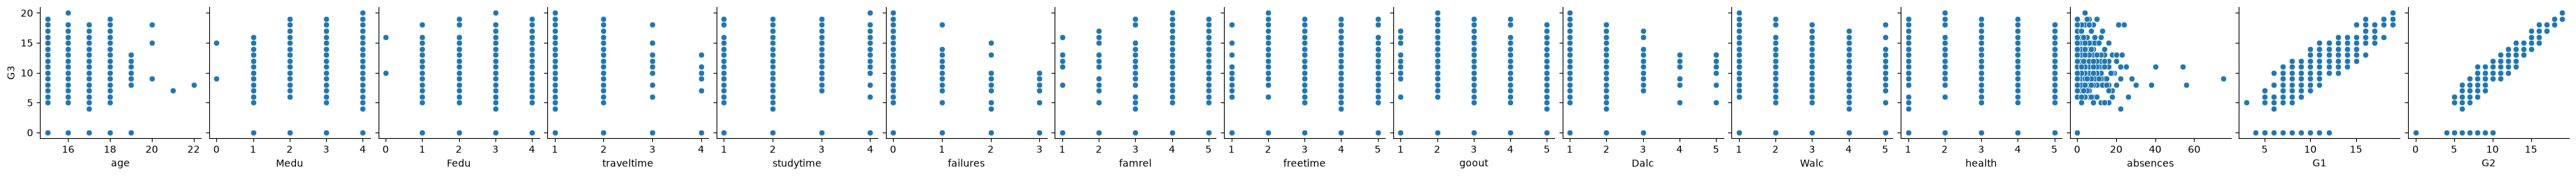

In [81]:
sns.pairplot(dataset, y_vars=['G3'], x_vars=dataset.columns[:-1], kind='scatter')

Con esta información

Predeciremos la nota final (G3) sin utilizar G1 ni G2.

Este enfoque es más difícil, pero permite estudiar si los factores demográficos, sociales, familiares y escolares ayudan a anticipar el rendimiento académico antes de conocer las notas de los periodos anteriores.



#### Train Test Split

Diferenciamos entre features and target para cada asignatura (Matemáticas y Portugués)

In [82]:
features_mat = dataset.drop(columns = ["G3"])
target_mat = dataset["G3"]

##features_por = dataset.drop(columns = ["G3_por"])
##target_por = dataset["G3_por"]

In [83]:
#MATEMATICAS

X_train_mat, X_test_mat, y_train_mat, y_test_mat = train_test_split(features_mat, target_mat, test_size = 0.20, random_state=0)

In [84]:
X_train_mat.head(5)

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
64,15,4,3,1,2,0,4,4,4,2,4,2,0,10,10
55,16,2,1,1,2,0,5,3,4,1,1,2,8,8,9
343,17,2,2,1,2,1,3,3,1,1,2,4,0,9,8
219,17,2,2,1,3,0,4,3,3,1,1,4,4,9,10
366,18,4,4,2,3,0,4,2,2,2,2,5,0,13,13


In [85]:
y_train_mat.head(5)

64     10
55     10
343     0
219    10
366    13
Name: G3, dtype: int64

In [86]:
#PORTUGUÉS

#X_train_por, X_test_por, y_train_por, y_test_por = train_test_split(features_por, target_por, test_size = 0.20, random_state=0)

In [87]:
#X_train_por.head(5)

In [88]:
#y_train_por.head(5)

Ahora utilizamos KNN de tipo Regressor

In [89]:
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(n_neighbors=4)

In [90]:
#MATEMATICAS

knn.fit(X_train_mat, y_train_mat)

knn.score(X_test_mat, y_test_mat)

0.8481889802650684

**En este caso, un resultado de 0,8481889 indica que el modelo tiene capacidad predictiva, aunque conviene compararlo con otros modelos para saber si es una buena opción.**

In [91]:
#PORTUGUÉS

#knn.fit(X_train_por, y_train_por)

#knn.score(X_test_por, y_test_por)

**En este caso, un resultado de 0,7099 indica que el modelo tiene capacidad predictiva, aunque conviene compararlo con otros modelos para saber si es una buena opción.**

## Feature Selection

Aunque normalizar nuestros datos tuvo un gran impacto en el rendimiento de KNN, actualmente estamos usando cada una de las características del conjunto de datos.

Ahora hagamos una selección de características basada en las correlaciones entre ellas, pero también con el objetivo.

Queremos baja correlación entre características, pero alta correlación entre las características y nuestro objetivo.

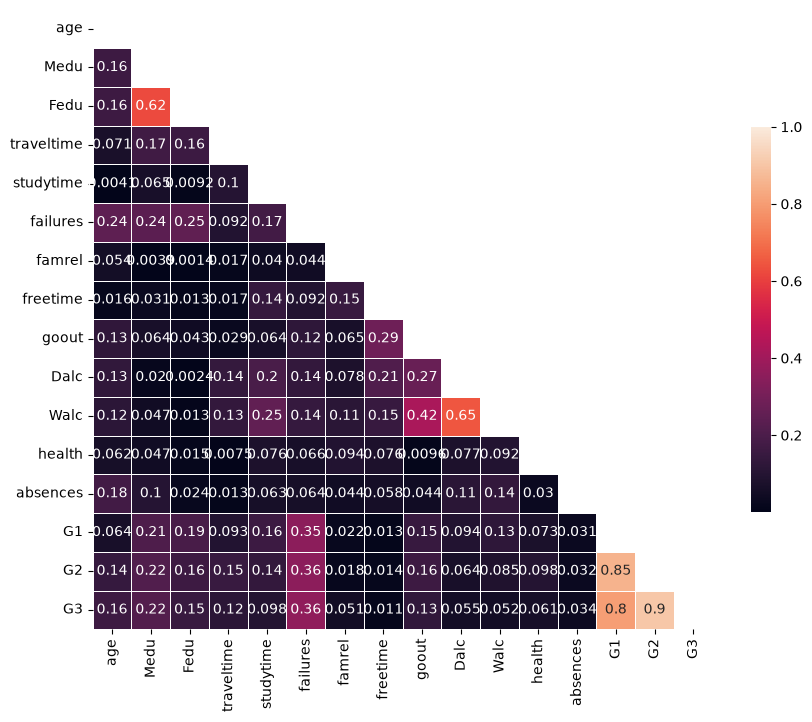

In [92]:
corr=np.abs(dataset.corr())

#Set up mask for triangle representation
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(10, 10))
# Generate a custom diverging colormap
cmap = sns.diverging_palette(220, 10, as_cmap=True)
# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask,  vmax=1,square=True, linewidths=.5, cbar_kws={"shrink": .5},annot = corr)

plt.show()

Por la matriz de correlación podemos ver que:
- "AveRooms" está muy correlacionado con "AveBedrms", así que eliminamos el que tenga menos correlación con nuestra variable objetivo
- "AveOccup" y "Population" también tienen una correlación bastante baja con nuestra variable objetivo, así que vamos a eliminarlos de nuestras características seleccionadas

In [93]:
X_train_mat_1 = X_train_mat.drop(columns = ["absences", "health", "Walc","Dalc","famrel","studytime"])
X_test_mat_1 = X_test_mat.drop(columns = ["absences", "health", "Walc","Dalc","famrel","studytime"])

In [94]:
knn = KNeighborsRegressor(n_neighbors=6)
knn.fit(X_train_mat_1, y_train_mat)

knn.score(X_test_mat_1, y_test_mat)

0.7580888246158135

**En este caso, un resultado de 0,8082 indica que el modelo tiene capacidad predictiva, aunque conviene compararlo con otros modelos para saber si es una buena opción.**

**Al normalizar nuestros datos y seleccionar un subconjunto de las características disponibles, pudimos ver que R1 es 0,8481889 y R2 ahora es 0.7580**

Probamos con otras variables

In [95]:
X_train_mat_2 = X_train_mat.drop(columns = ["age","Medu","Fedu","goout","failures","studytime"])
X_test_mat_2 = X_test_mat.drop(columns = ["age","Medu","Fedu","goout","failures","studytime"])

In [96]:
knn = KNeighborsRegressor(n_neighbors=6)
knn.fit(X_train_mat_2, y_train_mat)

knn.score(X_test_mat_2, y_test_mat)

0.8636931657587127

**En este caso, un resultado de 0,8082 indica que el modelo tiene capacidad predictiva, aunque conviene compararlo con otros modelos para saber si es una buena opción.**

**Al normalizar nuestros datos y seleccionar un subconjunto de las características disponibles, pudimos ver que R1 es 0,8481889 y R2 ahora es 0.8636**

Probamos nuevamente otras variables. Son las que menos se correlacionan: freetime, famrel, health

In [97]:
X_train_mat_def = X_train_mat.drop(columns = ["freetime","famrel","health"])
X_test_mat_def = X_test_mat.drop(columns = ["freetime","famrel","health"])

In [98]:
knn = KNeighborsRegressor(n_neighbors=6)
knn.fit(X_train_mat_def, y_train_mat)

knn.score(X_test_mat_def, y_test_mat)

0.8082782882195714

**En este caso, un resultado de 0,8082 indica que el modelo tiene capacidad predictiva, aunque conviene compararlo con otros modelos para saber si es una buena opción.**

**Al normalizar nuestros datos y seleccionar un subconjunto de las características disponibles, pudimos ver que R1 es 0,8481889 y R2 ahora es 0.8082**

In [99]:
dataset = pd.DataFrame({
    'Colour': ['Red', 'Blue', 'Green', 'Red', 'Blue'],
    'G3': [10, 12, 15, 11, 13]
})

In [100]:
dataset

,Colour,G3
0,Red,10
1,Blue,12
2,Green,15
3,Red,11
4,Blue,13


In [101]:
dataset_encoded = pd.get_dummies(dataset, columns=['Colour'], drop_first=False, dtype = int)
print(dataset_encoded)

   G3  Colour_Blue  Colour_Green  Colour_Red
0  10            0             0           1
1  12            1             0           0
2  15            0             1           0
3  11            0             0           1
4  13            1             0           0


In [102]:

from sklearn.preprocessing import LabelEncoder

dataset = pd.DataFrame({
    'Size': ['S', 'M', 'L', 'M', 'S'],
    'G3': [10, 12, 15, 11, 13]
})

print(dataset)

  Size  G3
0    S  10
1    M  12
2    L  15
3    M  11
4    S  13


In [103]:
mapa = {'S': 0, 'M': 1, 'L': 2}
dataset['Size_encoded'] = dataset['Size'].map(mapa)
print(dataset)


  Size  G3  Size_encoded
0    S  10             0
1    M  12             1
2    L  15             2
3    M  11             1
4    S  13             0


## Linear Regression

In [104]:
lin_reg = LinearRegression()

Training Linear Regression with our normalized data

In [105]:
lin_reg.fit(X_train_mat_def, y_train_mat)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[-0.22, 0.13,-0.19,..., 0.05, 0.12, 0.99]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['age','Medu','Fedu',...,'absences','G1','G2']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.163
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)


In [106]:
pred = lin_reg.predict(X_test_mat_def)

print("MAE", mean_absolute_error(pred, y_test_mat))
#print("RMSE", mean_squared_error(pred, y_test, squared=False))
print("R2 score", lin_reg.score(X_test_mat_def, y_test_mat))

MAE 1.4629287142494012
R2 score 0.7990586506621995


In [107]:
lin_reg_coef = {feature : coef for feature, coef in zip(X_train_mat_def.columns, lin_reg.coef_)}
lin_reg_coef

{'age': np.float64(-0.22482478688994753),
 'Medu': np.float64(0.1275565945701997),
 'Fedu': np.float64(-0.18818823544688504),
 'traveltime': np.float64(0.09036592646479136),
 'studytime': np.float64(-0.009312002416127365),
 'failures': np.float64(-0.23128329854819435),
 'goout': np.float64(-0.02425592164478048),
 'Dalc': np.float64(-0.10928021462583956),
 'Walc': np.float64(0.13272167969360582),
 'absences': np.float64(0.05182666542142511),
 'G1': np.float64(0.11701427871219769),
 'G2': np.float64(0.9855137589302561)}

Puedo concluir que G2 tiene mayor media

## Tree Instance

In [108]:
tree = DecisionTreeRegressor(max_depth=8)

tree.fit(X_train_mat_def, y_train_mat)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",8
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes m

In [109]:
X_train_mat_def

,age,Medu,Fedu,traveltime,studytime,failures,goout,Dalc,Walc,absences,G1,G2
64,15,4,3,1,2,0,4,2,4,0,10,10
55,16,2,1,1,2,0,4,1,1,8,8,9
343,17,2,2,1,2,1,1,1,2,0,9,8
219,17,2,2,1,3,0,3,1,1,4,9,10
366,18,4,4,2,3,0,2,2,2,0,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...
323,17,3,1,1,3,0,3,2,3,1,12,14
192,17,1,2,2,2,0,4,4,5,12,7,8
117,16,3,3,2,1,0,2,1,1,0,13,14
47,16,4,3,1,4,0,2,1,1,4,19,19


In [110]:
y_test_mat

329    14
318    10
317     9
65     15
59     16
       ..
276     9
140     0
142    11
306    18
146     0
Name: G3, Length: 79, dtype: int64

In [111]:
pred = tree.predict(X_test_mat_def)

print("MAE", mean_absolute_error(pred, y_test_mat))
##print("RMSE", mean_squared_error(pred, y_test, squared=False))
print("R2 score", tree.score(X_test_mat_def, y_test_mat))

MAE 1.0588340983910602
R2 score 0.846592176320925


In [112]:
tree_importance = {feature : importance for feature, importance in zip(X_train_mat_def.columns, tree.feature_importances_)}
tree_importance 

{'age': np.float64(0.0192140874743309),
 'Medu': np.float64(0.026226668456753616),
 'Fedu': np.float64(0.018031129838446944),
 'traveltime': np.float64(0.00045255727439407677),
 'studytime': np.float64(0.0029145017746707476),
 'failures': np.float64(0.003521657581766441),
 'goout': np.float64(0.001469836365916135),
 'Dalc': np.float64(0.0030883736746277614),
 'Walc': np.float64(0.009909633335042313),
 'absences': np.float64(0.13132962825755234),
 'G1': np.float64(0.012583942932055295),
 'G2': np.float64(0.7712579830344435)}

**Vemos que G2 sigue siendo la variable con mas media. Es importante destacar que se reduce este valor en comparación al modelo Linear Regression.**

In [113]:
from sklearn.tree import export_text

tree_viz = export_text(tree, feature_names=list(X_train_mat_def.columns))
print(tree_viz)

|--- G2 <= 9.50
|   |--- absences <= 1.00
|   |   |--- G2 <= 6.50
|   |   |   |--- value: [0.00]
|   |   |--- G2 >  6.50
|   |   |   |--- age <= 16.50
|   |   |   |   |--- Medu <= 1.50
|   |   |   |   |   |--- value: [0.00]
|   |   |   |   |--- Medu >  1.50
|   |   |   |   |   |--- G2 <= 7.50
|   |   |   |   |   |   |--- goout <= 2.50
|   |   |   |   |   |   |   |--- value: [6.00]
|   |   |   |   |   |   |--- goout >  2.50
|   |   |   |   |   |   |   |--- value: [8.00]
|   |   |   |   |   |--- G2 >  7.50
|   |   |   |   |   |   |--- studytime <= 2.50
|   |   |   |   |   |   |   |--- goout <= 1.50
|   |   |   |   |   |   |   |   |--- value: [11.00]
|   |   |   |   |   |   |   |--- goout >  1.50
|   |   |   |   |   |   |   |   |--- value: [10.00]
|   |   |   |   |   |   |--- studytime >  2.50
|   |   |   |   |   |   |   |--- value: [8.00]
|   |   |   |--- age >  16.50
|   |   |   |   |--- Walc <= 1.50
|   |   |   |   |   |--- Medu <= 2.50
|   |   |   |   |   |   |--- Medu <= 1.50
|   |  

**2. Comparación entre valores reales y predicciones**

Este gráfico compara el número de estudiantes de cada clase real con el número que predice el modelo.

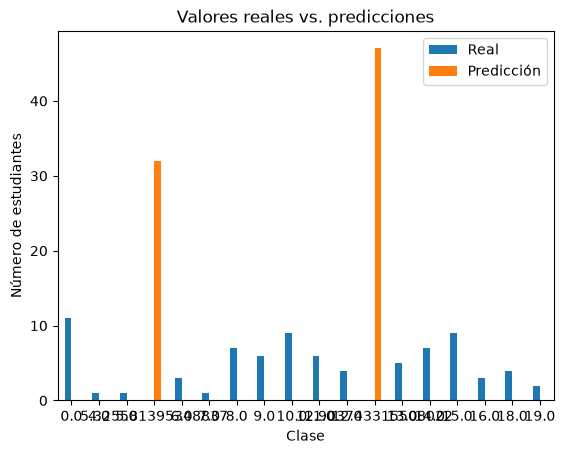

In [123]:
import pandas as pd
import matplotlib.pyplot as plt

resultados = pd.DataFrame({
    "Real": y_test_mat,
    "Predicción": pred
})

comparacion = pd.concat([
    resultados["Real"].value_counts().rename("Real"),
    resultados["Predicción"].value_counts().rename("Predicción")
], axis=1).sort_index()

comparacion.plot(kind="bar")
plt.title("Valores reales vs. predicciones")
plt.xlabel("Clase")
plt.ylabel("Número de estudiantes")
plt.xticks(rotation=0)
plt.show()

Miramos modleos diferentes de esemble: Bagging and Pasting, Random Forests, Gradient Boosting and Adaptative Boosting

In [115]:
#creamos una instancia del normalizador

from sklearn.preprocessing import MinMaxScaler


normalizer = MinMaxScaler()

normalizer.fit(X_train_mat_def)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](12,)","[22., 4., 4.,...,56.,19.,19.]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](12,)","[15., 0., 1.,..., 0., 3., 0.]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](12,)","[ 7., 4., 3.,...,56.,16.,19.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['age','Medu','Fedu',...,'absences','G1','G2']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](12,)","[-2.14, 0. ,-0.33,..., 0. ,-0.19, 0. ]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,316


In [116]:
X_train_norm = normalizer.transform(X_train_mat_def)

X_test_norm = normalizer.transform(X_test_mat_def)

X_train_norm = pd.DataFrame(X_train_norm, columns = X_train_mat_def.columns)

X_train_norm.head()

,age,Medu,Fedu,traveltime,studytime,failures,goout,Dalc,Walc,absences,G1,G2
0,0.000000,1.0,0.666667,0.000000,0.333333,0.000000,0.75,0.25,0.75,0.000000,0.4375,0.526316
1,0.142857,0.5,0.000000,0.000000,0.333333,0.000000,0.75,0.00,0.00,0.142857,0.3125,0.473684
2,0.285714,0.5,0.333333,0.000000,0.333333,0.333333,0.00,0.00,0.25,0.000000,0.3750,0.421053
3,0.285714,0.5,0.333333,0.000000,0.666667,0.000000,0.50,0.00,0.00,0.071429,0.3750,0.526316
4,0.428571,1.0,1.000000,0.333333,0.666667,0.000000,0.25,0.25,0.25,0.000000,0.6250,0.684211


In [117]:
X_test_norm = pd.DataFrame(X_test_norm, columns = X_test_mat_def.columns)

X_test_norm.head()

,age,Medu,Fedu,traveltime,studytime,failures,goout,Dalc,Walc,absences,G1,G2
0,0.285714,1.00,1.000000,0.333333,0.666667,0.0,0.50,0.00,0.25,0.071429,0.6875,0.736842
1,0.285714,0.75,1.000000,0.000000,0.666667,0.0,0.75,0.25,1.00,0.000000,0.5000,0.578947
2,0.428571,1.00,0.666667,0.000000,0.666667,0.0,0.75,0.00,0.00,0.160714,0.3750,0.526316
3,0.142857,1.00,0.666667,0.666667,0.333333,0.0,0.50,0.00,0.25,0.035714,0.8125,0.789474
4,0.142857,1.00,0.333333,0.000000,0.333333,0.0,0.50,0.00,0.00,0.035714,0.7500,0.842105


## Bagging and Pasting

In [118]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor


bagging_reg = BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=20),
    n_estimators=100,
    max_samples=1000,
    random_state=0
)

bagging_reg.fit(X_train_norm, y_train_mat)


pred = bagging_reg.predict(X_test_norm)


print("Test accuracy:", bagging_reg.score(X_test_norm, y_test_mat))

Test accuracy: 0.8729835337027099


## Random Forests

In [119]:
from sklearn.ensemble import RandomForestRegressor


forest = RandomForestRegressor(n_estimators=100,
                             max_depth=20)

forest.fit(X_train_norm, y_train_mat)

pred = forest.predict(X_test_norm)

print("Test Acurracy", forest.score(X_test_norm, y_test_mat))

Test Acurracy 0.8730756641228468


## Gradient Boosting

In [120]:
from sklearn.ensemble import GradientBoostingRegressor


gb_reg = GradientBoostingRegressor(max_depth=20,
                                   n_estimators=100)

gb_reg.fit(X_train_norm, y_train_mat)

pred = gb_reg.predict(X_test_norm)

print("Test Acurracy", gb_reg.score(X_test_norm, y_test_mat))

Test Acurracy 0.8351636736243536


## Adaptive Boosting

In [121]:
from sklearn.ensemble import AdaBoostRegressor


ada_clf = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=1),
    n_estimators=100,
    random_state=0
)

ada_clf.fit(X_train_norm, y_train_mat)

pred = ada_clf.predict(X_test_norm)


print("Test accuracy:", ada_clf.score(X_test_norm, y_test_mat))

Test accuracy: 0.5418597498631834



### **Tabla de resultados de diferentes modelos**
| Modelo                  | Resultado |
|-------------------------|----------:|
| KNN                     | 0,7099    |
| Feature selection       | 0,8082    |
| Linear regression       | 0,7990    |
| Tree instance           | 0,8465    |
| Bagging and pasting     | 0,8729    |
| Random forests          | **0,8730** |
| Gradient boosting       | 0,8351    |
| Adaptive boosting       | 0,5418    |

## Streamlit

In [126]:
import pip
%pip install streamlit
import streamlit


Note: you may need to restart the kernel to use updated packages.


In [130]:
import streamlit as st
import streamlit as st
import streamlit as st